# Member 2 — Midterm: Exploratory Data Analysis & RFM Segmentation

**Assumed member allocation:** No assignment breakdown was present in the ZIP. This notebook handles EDA, RFM scoring, and preliminary customer segments. Uses the already-preprocessed 5,878-customer dataset; no need to unpack the original 95 MB CSV.

- Recency: days since last purchase (lower is better)
- Frequency: number of distinct invoices (higher is better)
- Monetary: total positive invoice-line value (higher is better)

**Note:** Cancellations/refunds were excluded by preprocessing, so monetary totals reflect positive purchases, not net revenue.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA_DIR = Path('dataset') if Path('dataset/rfm_raw.csv').exists() else Path('notebooks/dataset')
OUT_DIR = DATA_DIR.resolve().parent.parent / 'outputs'
OUT_DIR.mkdir(parents=True, exist_ok=True)
rfm = pd.read_csv(DATA_DIR/'rfm_raw.csv')
assert rfm['CustomerID'].is_unique and not rfm[['Recency','Frequency','Monetary']].isna().any().any()
print(f'Loaded {len(rfm):,} customers; outputs -> {OUT_DIR.resolve()}')

Loaded 5,878 customers; outputs -> /mnt/data/ecommerce_work/DataMining-Ecommerce-Analytics-main/outputs


In [2]:
print('Shape:',rfm.shape)
print(rfm[['Recency','Frequency','Monetary']].describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
print('Skewness:',rfm[['Recency','Frequency','Monetary']].skew().round(2).to_dict())
print('Duplicate customer IDs:',rfm.CustomerID.duplicated().sum())

Shape: (5878, 4)
       Recency  Frequency   Monetary
count  5878.00    5878.00    5878.00
mean    201.33       6.29    2955.90
std     209.34      13.01   14440.85
min       1.00       1.00       2.95
25%      26.00       1.00     342.28
50%      96.00       3.00     867.74
75%     380.00       7.00    2248.30
90%     535.00      13.00    5465.74
95%     625.00      21.00    9374.23
99%     726.00      46.00   29205.90
max     739.00     398.00  580987.04
Skewness: {'Recency': 0.89, 'Frequency': 12.64, 'Monetary': 25.07}
Duplicate customer IDs: 0


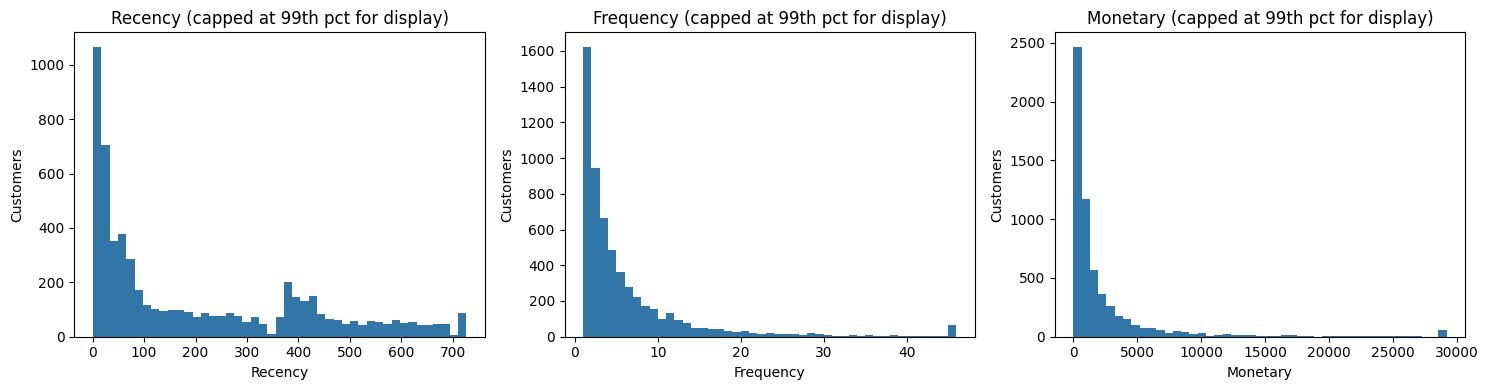

In [3]:
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axs,['Recency','Frequency','Monetary']):
    ax.hist(rfm[col].clip(upper=rfm[col].quantile(.99)),bins=45,color='#3276a8')
    ax.set(title=f'{col} (capped at 99th pct for display)',xlabel=col,ylabel='Customers')
fig.tight_layout();fig.savefig(OUT_DIR/'member2_rfm_distributions.png',dpi=150);plt.show()

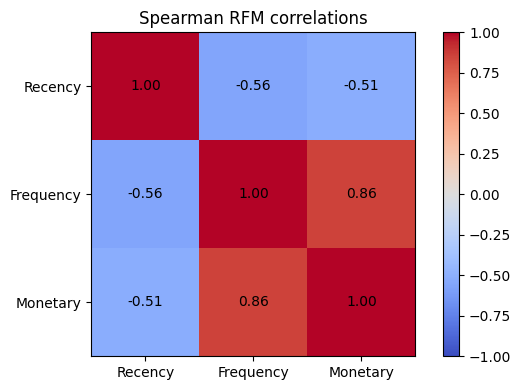

In [4]:
fig,ax=plt.subplots(figsize=(6,4))
corr=rfm[['Recency','Frequency','Monetary']].corr(method='spearman')
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm'); ax.set_xticks(range(3),corr.columns);ax.set_yticks(range(3),corr.columns)
for i in range(3):
 for j in range(3):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax);ax.set_title('Spearman RFM correlations');fig.tight_layout();fig.savefig(OUT_DIR/'member2_rfm_correlation.png',dpi=150);plt.show()

## RFM scoring
Each metric is ranked into five approximately equal-sized groups using rank-based quantiles to handle tied values. A high score is desirable; **Recency is reversed**. These are relative scores within the dataset, not absolute customer benchmarks.

In [5]:
scored=rfm.copy()
for name,reverse in [('Recency',True),('Frequency',False),('Monetary',False)]:
    rank=scored[name].rank(method='first',ascending=True)
    pts=pd.qcut(rank,5,labels=False).astype(int)+1
    scored[name[0]+'_Score']=6-pts if reverse else pts
scored['RFM_Score']=scored[['R_Score','F_Score','M_Score']].sum(axis=1)
def segment(row):
    r,f,m=row['R_Score'],row['F_Score'],row['M_Score']
    if r>=4 and f>=4 and m>=4:return 'Champions'
    if r>=4 and f>=3:return 'Loyal / active'
    if r<=2 and f>=4:return 'At-risk high-frequency'
    if r<=2:return 'Inactive / slipping'
    if r>=4:return 'Recent / developing'
    return 'Regular'
scored['Segment']=scored.apply(segment,axis=1)
summary=scored.groupby('Segment').agg(Customers=('CustomerID','size'),Median_Recency=('Recency','median'),Median_Frequency=('Frequency','median'),Median_Monetary=('Monetary','median'),Total_Monetary=('Monetary','sum')).sort_values('Customers',ascending=False)
summary['Share_%']=(summary['Customers']/len(scored)*100).round(1)
print(summary.round(2).to_string())
scored.to_csv(OUT_DIR/'member2_rfm_segments.csv',index=False)
summary.to_csv(OUT_DIR/'member2_segment_summary.csv')

                        Customers  Median_Recency  Median_Frequency  Median_Monetary  Total_Monetary  Share_%
Segment                                                                                                      
Inactive / slipping          1997           422.0               1.0           339.75      1154134.72     34.0
Champions                    1289            16.0              11.0          3949.60     11819626.88     21.9
Regular                      1176            96.0               4.0          1052.80      2275628.51     20.0
Loyal / active                621            22.0               3.0           856.03       641881.36     10.6
Recent / developing           441            26.0               1.0           372.22       391838.26      7.5
At-risk high-frequency        354           337.5               6.0          1561.58      1091694.54      6.0


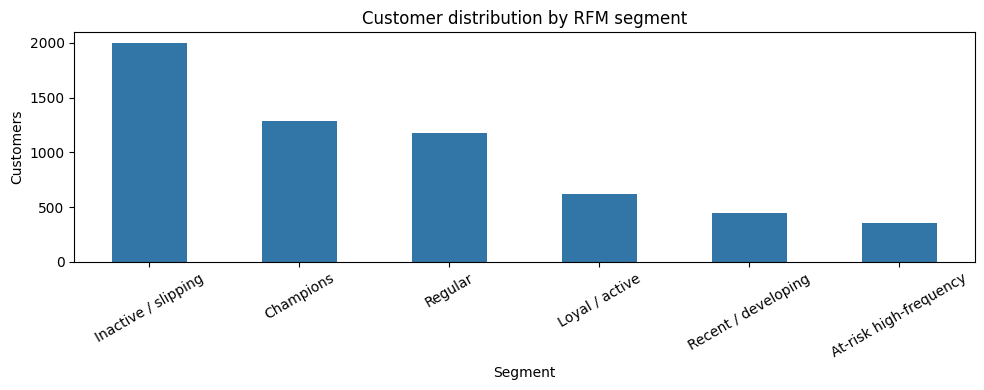

In [6]:
fig,ax=plt.subplots(figsize=(10,4));summary['Customers'].plot.bar(ax=ax,color='#3276a8');ax.set(ylabel='Customers',title='Customer distribution by RFM segment');ax.tick_params(axis='x',rotation=30);fig.tight_layout();fig.savefig(OUT_DIR/'member2_segment_counts.png',dpi=150);plt.show()

## Interpretation
- **Champions**: recent, repeat, high-spending customers; prioritize retention benefits.
- **At-risk high-frequency**: previously frequent buyers with long inactivity; consider win-back campaigns.
- **Recent / developing**: newly active but not yet high-frequency buyers; encourage a second or third purchase.
- Segment thresholds are heuristic and do not prove causality or actual churn.